# AlphaGenome Atlas: in silico mutagenesis across BRCA1

The AlphaGenome Atlas holds pre-computed scores for every possible single-nucleotide
variant in the human genome. Here we pull all SNVs across BRCA1 and its flanking
non-coding sequence (hg38), and for every position plot the effect of the
**maximum-effect substitution** (the ALT base with the largest |score| out of the three).

Scores are for mammary epithelial cells (`CL:0002327`) where the scorer is tissue specific.

In [1]:
import pathlib
import time

from alphagenome.atlas import atlas
from alphagenome.data import genome
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = pathlib.Path('/storage/mathelierarea/processed/eirikhoy/action_var')

GENE = 'BRCA1'
ONTOLOGY = 'CL:0002327'  # mammary epithelial cell
# BRCA1 (minus strand, MANE transcript chr17:43,044,295-43,125,364) plus ~14 kb of
# 3' flank and ~25 kb of 5' flank (shared promoter with NBR2 and beyond).
REGION = genome.Interval('chr17', 43_030_000, 43_150_000)
SCORERS = ['AVI_SCORE', 'RNA_SEQ', 'SPLICE_SITES', 'DNASE', 'CAGE', 'CHIP_HISTONE']
CHUNK = 4_000
CACHE = ROOT / 'data/alphagenome_atlas' / GENE
CACHE.mkdir(parents=True, exist_ok=True)

atlas_client = atlas.create((ROOT / 'resources/API_KEY').read_text().strip(), timeout=60)

In [2]:
# Scorers available in the Atlas.
pd.DataFrame(
    [
        {'scorer': name, 'signed': m.is_signed, 'n_tracks': len(m.track_metadata)}
        for name, m in atlas_client.scorer_metadata().items()
    ]
)

,scorer,signed,n_tracks
0,AVI_SCORE,False,1
1,AVI_SCORE_FEATURE_IMPORTANCE,False,18
2,AVI_SCORE_MODEL_FEATURES,True,18
3,CHIP_HISTONE_ACTIVE,False,1116
4,ATAC_ACTIVE,False,167
5,CAGE_ACTIVE,False,546
6,CHIP_TF_ACTIVE,False,1617
7,DNASE_ACTIVE,False,305
8,PROCAP_ACTIVE,False,12
9,CHIP_HISTONE,True,1116


## Fetch every SNV in the region

`query_interval` returns all three substitutions at every position. The region is
fetched in 4 kb chunks that are cached as parquet, so re-running is instant.
The first run takes roughly 10 minutes for 120 kb (360,000 variants).

In [3]:
def tidy_atlas(result):
    """One row per variant, one column per scorer track (raw score, and `|q` quantile)."""
    frames = []
    for scorer, ad in result.items():
        if ad.n_obs == 0:  # e.g. splice scores outside the gene body
            continue
        names = (
            ad.var['name']
            .str.replace(ONTOLOGY, '')
            .str.replace('Histone ChIP-seq', '')
            .str.strip()
        )
        strands = ad.var['strand'].map(lambda s: '' if s == '.' else f':{s}')
        cols = [f'{scorer}:{n}{s}' for n, s in zip(names, strands)]
        df = pd.DataFrame(ad.X, columns=cols)
        if 'quantiles' in ad.layers:
            df = df.join(
                pd.DataFrame(ad.layers['quantiles'], columns=[c + '|q' for c in cols])
            )
        df['variant'] = ad.obs['variant'].astype(str).values
        if 'gene_name' in ad.obs:
            df = df[(ad.obs['gene_name'] == GENE).values]
        frames.append(df.drop_duplicates('variant').set_index('variant'))
    out = pd.concat(frames, axis=1).reset_index()
    parts = out['variant'].str.extract(
        r'^(?P<chrom>[^:]+):(?P<pos>\d+):(?P<ref>[ACGTN]+)>(?P<alt>[ACGTN]+)$'
    )
    out = pd.concat([parts.astype({'pos': int}), out.drop(columns='variant')], axis=1)
    return out.sort_values(['pos', 'alt']).reset_index(drop=True)


def fetch_region(region):
    """Fetch every SNV in `region` from the Atlas, in cached chunks."""
    frames = []
    for start in range(region.start, region.end, CHUNK):
        chunk = genome.Interval(region.chromosome, start, min(start + CHUNK, region.end))
        path = CACHE / f'{chunk.chromosome}_{chunk.start}_{chunk.end}.parquet'
        if not path.exists():
            for attempt in range(5):
                try:
                    result = atlas_client.query_interval(
                        chunk,
                        requested_scorers=SCORERS,
                        ontology_terms=[ONTOLOGY],
                        gene_names=[GENE],
                        progress_bar=False,
                    )
                    break
                except Exception as e:  # transient gRPC errors
                    print('retry', chunk, type(e).__name__, str(e)[:200])
                    time.sleep(10 * (attempt + 1))
            else:
                raise RuntimeError(f'failed {chunk}')
            tidy_atlas(result).to_parquet(path)
        frames.append(pd.read_parquet(path))
    return pd.concat(frames, ignore_index=True)


ISM = fetch_region(REGION)
print(f'{len(ISM):,} variants at {ISM.pos.nunique():,} positions')
ISM.head()

360,000 variants at 120,000 positions


,chrom,pos,ref,alt,CAGE:hCAGE:+,CAGE:hCAGE:-,CAGE:hCAGE:+|q,CAGE:hCAGE:-|q,CHIP_HISTONE:H2AFZ,CHIP_HISTONE:H3K27ac,...,RNA_SEQ:polyA plus RNA-seq,RNA_SEQ:total RNA-seq,RNA_SEQ:polyA plus RNA-seq|q,RNA_SEQ:total RNA-seq|q,AVI_SCORE:AVI_SCORE,AVI_SCORE:AVI_SCORE|q,SPLICE_SITES:donor,SPLICE_SITES:acceptor,SPLICE_SITES:donor|q,SPLICE_SITES:acceptor|q
0,chr17,43030001,T,A,-0.008915,-0.001459,-0.611615,-0.184217,-0.018422,-0.005581,...,-0.002084,-0.000488,-0.867120,-0.544025,-0.019819,0.343891,NaN,NaN,NaN,NaN
1,chr17,43030001,T,C,0.021463,-0.004190,0.844498,-0.371041,0.013397,0.000530,...,-0.000793,0.001325,-0.652282,0.788422,-0.008965,0.424261,NaN,NaN,NaN,NaN
2,chr17,43030001,T,G,-0.006685,-0.000662,-0.507261,-0.101294,-0.000179,-0.000796,...,-0.000032,0.001260,-0.248775,0.775255,-0.024224,0.312833,NaN,NaN,NaN,NaN
3,chr17,43030002,T,A,-0.028809,0.002754,-0.900303,0.200530,-0.009362,-0.003186,...,-0.000811,0.003896,-0.661907,0.970488,0.080885,0.820220,NaN,NaN,NaN,NaN
4,chr17,43030002,T,C,-0.036512,-0.007723,-0.927922,-0.555842,-0.054496,-0.024881,...,-0.001101,0.002718,-0.723420,0.930239,0.091934,0.836838,NaN,NaN,NaN,NaN


## Maximum-effect substitution per position

For signed scores (RNA-seq, DNase, CAGE, histone marks) the ALT base with the largest
absolute score is kept, with its sign. For unsigned scores (AVI, splice sites) the
largest score is kept.

In [4]:
ISM['SPLICE_SITES:max'] = ISM[['SPLICE_SITES:donor', 'SPLICE_SITES:acceptor']].max(axis=1)

# (panel title, column, signed)
TRACKS = [
    ('AlphaGenome Variant Impact (AVI) score', 'AVI_SCORE:AVI_SCORE', False),
    ('BRCA1 RNA-seq, log fold change', 'RNA_SEQ:polyA plus RNA-seq', True),
    ('BRCA1 splice site score (donor or acceptor)', 'SPLICE_SITES:max', False),
    ('DNase accessibility', 'DNASE:DNase-seq', True),
    ('CAGE, minus strand', 'CAGE:hCAGE:-', True),
    ('H3K4me3', 'CHIP_HISTONE:H3K4me3', True),
    ('H3K27ac', 'CHIP_HISTONE:H3K27ac', True),
]


def max_effect(df, col, signed):
    """Per position, the score and ALT base of the maximum-effect substitution."""
    key = df[col].abs() if signed else df[col]
    idx = key.fillna(-np.inf).groupby(df.pos).idxmax()
    out = df.loc[idx, ['pos', 'alt', col]].set_index('pos')
    return out[col], out['alt'].where(out[col].notna())


MAXEFF = ISM.groupby('pos').ref.first().to_frame()
for _, col, signed in TRACKS:
    MAXEFF[col], MAXEFF[col + '|alt'] = max_effect(ISM, col, signed)
MAXEFF['AVI_SCORE:AVI_SCORE|q'] = ISM.groupby('pos')['AVI_SCORE:AVI_SCORE|q'].max()
MAXEFF.head()

,ref,AVI_SCORE:AVI_SCORE,AVI_SCORE:AVI_SCORE|alt,RNA_SEQ:polyA plus RNA-seq,RNA_SEQ:polyA plus RNA-seq|alt,SPLICE_SITES:max,SPLICE_SITES:max|alt,DNASE:DNase-seq,DNASE:DNase-seq|alt,CAGE:hCAGE:-,CAGE:hCAGE:-|alt,CHIP_HISTONE:H3K4me3,CHIP_HISTONE:H3K4me3|alt,CHIP_HISTONE:H3K27ac,CHIP_HISTONE:H3K27ac|alt,AVI_SCORE:AVI_SCORE|q
pos,,,,,,,,,,,,,,,,
43030001,T,-0.008965,C,-0.002084,A,NaN,NaN,-0.020262,A,-0.004190,C,-0.010484,G,-0.005581,A,0.424261
43030002,T,0.091934,C,-0.001101,C,NaN,NaN,-0.057847,C,-0.007723,C,-0.015001,C,-0.024881,C,0.836838
43030003,G,0.210634,C,-0.002115,T,NaN,NaN,0.050261,C,-0.002700,T,0.027347,C,0.026284,C,0.934116
43030004,A,0.155763,T,-0.002150,T,NaN,NaN,0.032498,T,0.004607,C,0.008555,T,0.017663,T,0.901227
43030005,T,0.178823,G,-0.002080,C,NaN,NaN,0.018058,G,-0.003765,C,-0.005232,C,0.012414,G,0.916979


## Annotate positions: coding vs non-coding

In [5]:
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf = gtf[
    (gtf.Chromosome == REGION.chromosome)
    & (gtf.End > REGION.start)
    & (gtf.Start < REGION.end)
]
# MANE Select transcript of BRCA1 (GTF Start is 0-based, End is inclusive 1-based).
mane = gtf[
    (gtf.gene_name == GENE) & gtf.tag.str.contains('MANE_Select', na=False)
]
tx = mane[mane.Feature == 'transcript'].iloc[0]
TSS = tx.End if tx.Strand == '-' else tx.Start + 1
PROMOTER_BP = 1_000


def in_features(pos, feats):
    hit = np.zeros(len(pos), dtype=bool)
    for f in feats.itertuples():
        hit |= (pos > f.Start) & (pos <= f.End)
    return hit


pos = MAXEFF.index.values
upstream = pos > tx.End if tx.Strand == '-' else pos <= tx.Start
downstream = pos <= tx.Start if tx.Strand == '-' else pos > tx.End
region_class = np.full(len(pos), 'intron', dtype=object)
region_class[in_features(pos, mane[mane.Feature == 'exon'])] = 'UTR'
region_class[in_features(pos, mane[mane.Feature == 'CDS'])] = 'CDS'
region_class[upstream] = "5' flank"
region_class[upstream & (np.abs(pos - TSS) <= PROMOTER_BP)] = 'promoter (1 kb)'
region_class[downstream] = "3' flank"
MAXEFF['region'] = region_class
REGION_ORDER = ["5' flank", 'promoter (1 kb)', 'UTR', 'CDS', 'intron', "3' flank"]
MAXEFF.region.value_counts()[REGION_ORDER]

region
5' flank           23636
promoter (1 kb)     1000
UTR                 1499
CDS                 5589
intron             73982
3' flank           14294
Name: count, dtype: int64

## Overview across the whole locus

120 kb does not fit one bar per base, so each bar is a 100 bp bin showing the most
extreme max-effect substitution inside it (strongest increase and strongest decrease
for signed scores).

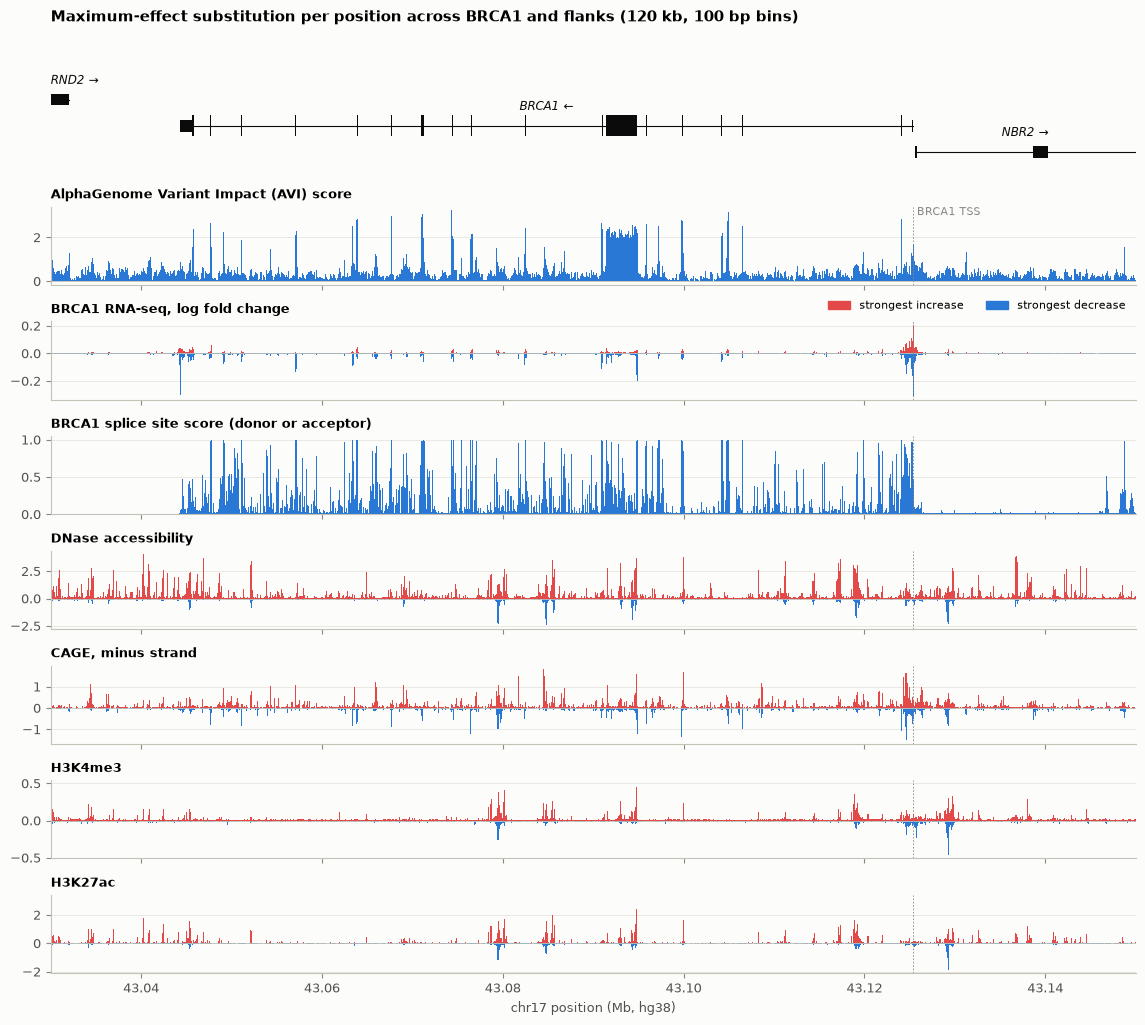

In [6]:
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'
UP, DOWN, MAGNITUDE = '#e34948', '#2a78d6', '#2a78d6'
NUC_COLORS = {'A': '#2a78d6', 'C': '#eb6834', 'G': '#1baf7a', 'T': '#eda100'}

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e',
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': '#52514e', 'ytick.labelcolor': '#52514e',
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 9, 'axes.titlesize': 9.5, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
})


def draw_genes(ax, start, end):
    """Draws transcripts in [start, end): tall boxes are CDS, short boxes are UTR."""
    genes = gtf[(gtf.Feature == 'gene') & gtf.gene_type.isin(['protein_coding', 'lncRNA'])]
    genes = genes[~genes.gene_name.str.startswith('ENSG')]
    for row, g in enumerate(genes.itertuples()):
        t = gtf[(gtf.gene_name == g.gene_name) & (gtf.Feature == 'transcript')]
        is_mane = t.tag.str.contains('MANE_Select', na=False)
        t = t[is_mane].iloc[0] if is_mane.any() else t.assign(w=t.End - t.Start).sort_values('w').iloc[-1]
        parts = gtf[gtf.transcript_id == t.transcript_id]
        y = -row
        lo, hi = max(t.Start, start), min(t.End, end)
        if lo >= hi:  # transcript is outside the window
            continue
        ax.plot([lo, hi], [y, y], color=INK, lw=0.8)
        for feature, h in [('exon', 0.22), ('CDS', 0.4)]:
            for f in parts[parts.Feature == feature].itertuples():
                ax.add_patch(plt.Rectangle((f.Start, y - h), f.End - f.Start, 2 * h, color=INK, lw=0))
        arrow = '←' if t.Strand == '-' else '→'
        # Keep labels of genes at the window edge inside the axes.
        frac = ((lo + hi) / 2 - start) / (end - start)
        ha = 'left' if frac < 0.08 else 'right' if frac > 0.92 else 'center'
        x_label = {'left': lo, 'right': hi, 'center': (lo + hi) / 2}[ha]
        ax.text(x_label, y + 0.5, f'{g.gene_name} {arrow}', ha=ha, va='bottom',
                fontsize=8.5, color=INK, style='italic')
    ax.set_ylim(-len(genes) + 0.3, 1.2)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.tick_params(bottom=False)


def plot_overview(bin_size=100):
    fig, axes = plt.subplots(
        len(TRACKS) + 1, 1, figsize=(14, 1.45 * len(TRACKS) + 1.6), sharex=True,
        gridspec_kw={'height_ratios': [1.3] + [1] * len(TRACKS), 'hspace': 0.45},
    )
    draw_genes(axes[0], REGION.start, REGION.end)
    bins = MAXEFF.index // bin_size * bin_size
    for ax, (title, col, signed) in zip(axes[1:], TRACKS):
        grouped = MAXEFF[col].groupby(bins)
        hi = grouped.max()
        if signed:
            lo = grouped.min()
            ax.bar(hi.index, hi.clip(lower=0), width=bin_size, align='edge', color=UP, lw=0)
            ax.bar(lo.index, lo.clip(upper=0), width=bin_size, align='edge', color=DOWN, lw=0)
        else:
            ax.bar(hi.index, hi, width=bin_size, align='edge', color=MAGNITUDE, lw=0)
        ax.axhline(0, color='#c3c2b7', lw=0.6)
        ax.axvline(TSS, color=MUTED, lw=0.6, ls=(0, (2, 2)))
        ax.set_title(title)
        ax.grid(axis='y', color=GRID, lw=0.5)
        ax.set_axisbelow(True)
        ax.locator_params(axis='y', nbins=3)
    axes[1].text(TSS, axes[1].get_ylim()[1], ' BRCA1 TSS', color=MUTED, fontsize=8, va='top')
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (UP, DOWN)]
    axes[2].legend(handles, ['strongest increase', 'strongest decrease'], frameon=False,
                   ncols=2, loc='lower right', bbox_to_anchor=(1, 1), fontsize=8)
    axes[-1].set_xlim(REGION.start, REGION.end)
    axes[-1].xaxis.set_major_formatter(lambda x, _: f'{x / 1e6:.2f}')
    axes[-1].set_xlabel(f'{REGION.chromosome} position (Mb, hg38)')
    fig.suptitle(
        f'Maximum-effect substitution per position across {GENE} and flanks '
        f'({REGION.width // 1000} kb, {bin_size} bp bins)',
        x=0.125, ha='left', fontsize=11, fontweight='bold', y=0.93,
    )
    return fig


fig = plot_overview()
fig.savefig(f'atlas_ism_{GENE}_overview.png', dpi=200, bbox_inches='tight')

## Zoom: one bar per base

Each bar is the maximum-effect substitution at that position, coloured by the ALT
base that causes it.

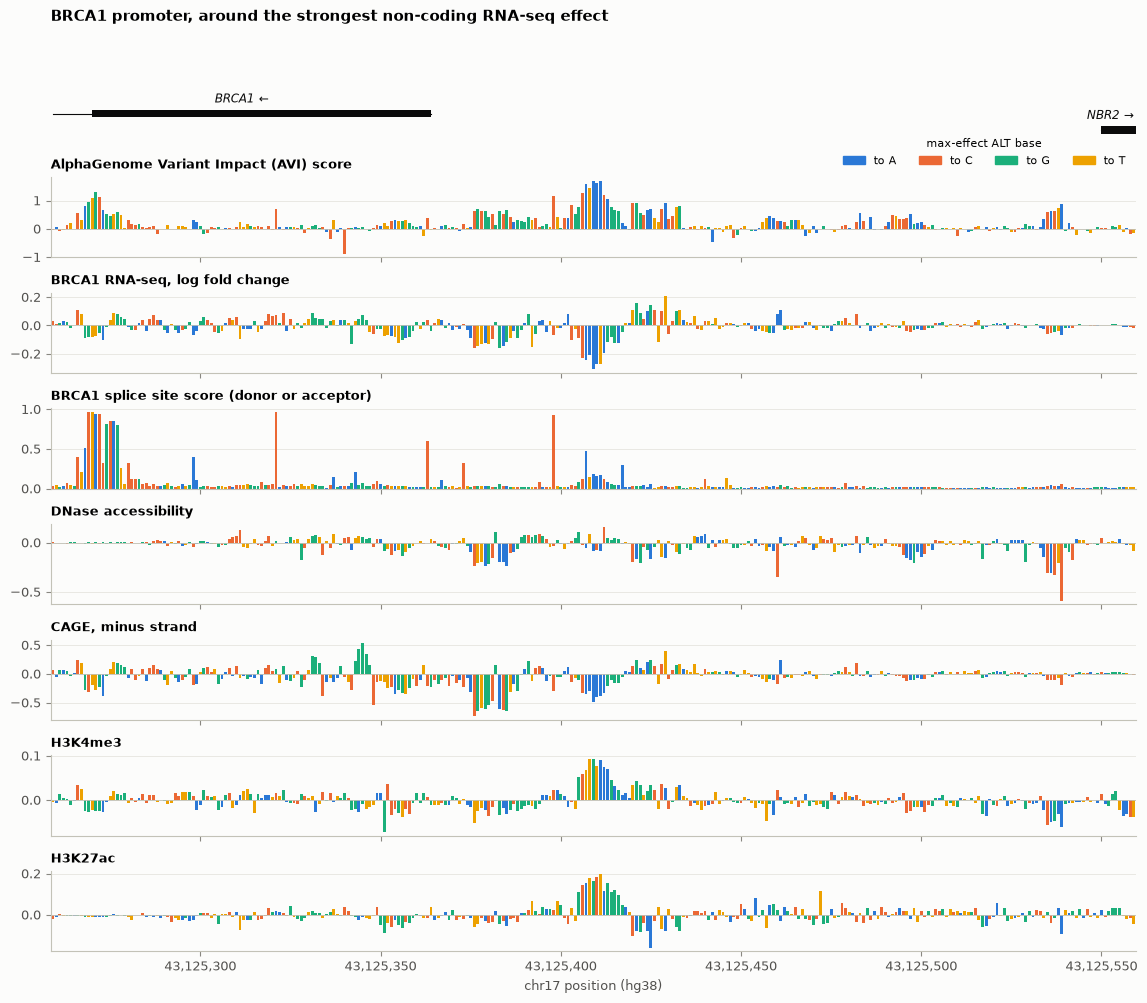

In [7]:
def plot_zoom(center, width=300, tracks=TRACKS, title=None):
    start, end = center - width // 2, center + width // 2
    win = MAXEFF.loc[start:end]
    fig, axes = plt.subplots(
        len(tracks) + 1, 1, figsize=(14, 1.45 * len(tracks) + 1.2), sharex=True,
        gridspec_kw={'height_ratios': [0.8] + [1] * len(tracks), 'hspace': 0.45},
    )
    draw_genes(axes[0], start, end)
    for ax, (name, col, _) in zip(axes[1:], tracks):
        colors = win[col + '|alt'].map(NUC_COLORS).fillna(GRID)
        ax.bar(win.index, win[col].fillna(0), width=0.8, color=colors, lw=0)
        ax.axhline(0, color='#c3c2b7', lw=0.6)
        ax.set_title(name)
        ax.grid(axis='y', color=GRID, lw=0.5)
        ax.set_axisbelow(True)
        ax.locator_params(axis='y', nbins=3)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in NUC_COLORS.values()]
    axes[1].legend(handles, [f'to {n}' for n in NUC_COLORS], frameon=False, ncols=4,
                   loc='lower right', bbox_to_anchor=(1, 1), fontsize=8,
                   title='max-effect ALT base', title_fontsize=8)
    axes[-1].set_xlim(start - 0.5, end + 0.5)
    if width <= 120:  # room to print the reference sequence
        axes[-1].set_xticks(win.index, win.ref, fontsize=7, family='monospace')
        axes[-1].tick_params(axis='x', length=0)
        axes[-1].set_xlabel(f'reference sequence, {REGION.chromosome}:{start:,}-{end:,} (hg38, + strand)')
    else:
        axes[-1].xaxis.set_major_formatter(lambda x, _: f'{int(x):,}')
        axes[-1].set_xlabel(f'{REGION.chromosome} position (hg38)')
    fig.suptitle(title or f'{REGION.chromosome}:{start:,}-{end:,}', x=0.125, ha='left',
                 fontsize=11, fontweight='bold', y=0.94)
    return fig


# Promoter: centred on the position with the largest predicted effect on BRCA1 RNA.
rna = 'RNA_SEQ:polyA plus RNA-seq'
top_rna = MAXEFF.loc[MAXEFF.region.isin(['promoter (1 kb)', "5' flank", 'UTR']), rna].abs().idxmax()
fig = plot_zoom(top_rna, width=300,
                title=f'{GENE} promoter, around the strongest non-coding RNA-seq effect')
fig.savefig(f'atlas_ism_{GENE}_promoter.png', dpi=200, bbox_inches='tight')

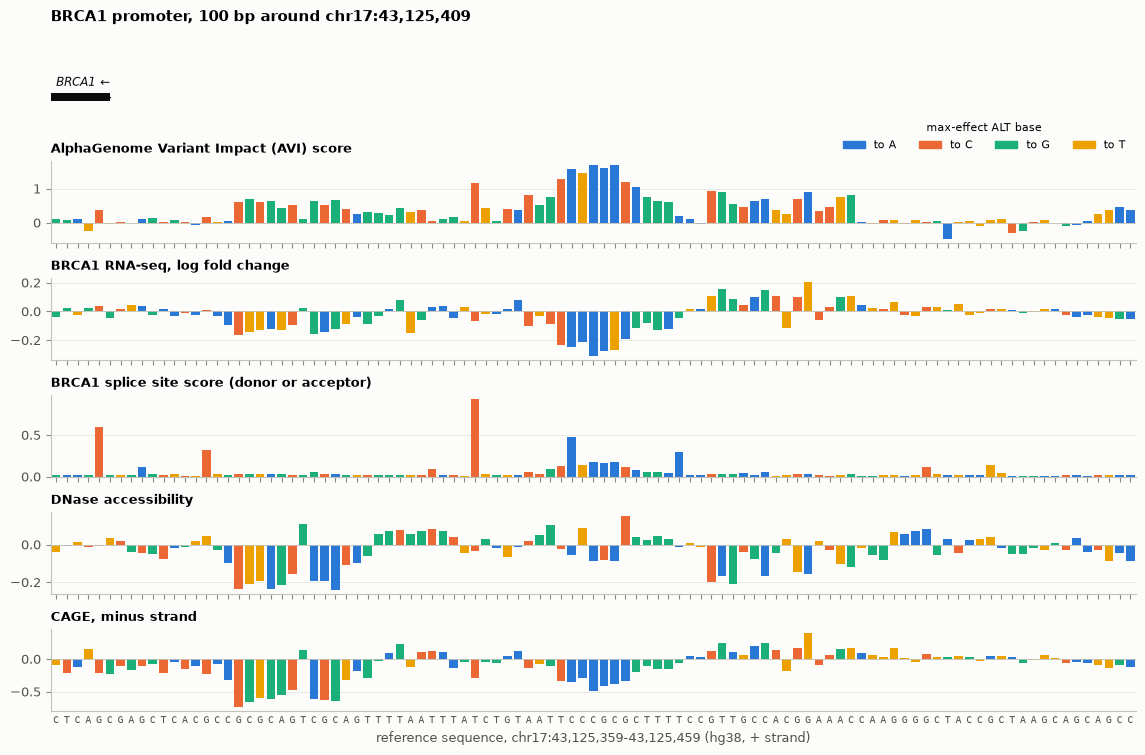

In [8]:
# Base-resolution view of the same site, with the reference sequence on the x axis.
fig = plot_zoom(top_rna, width=100, tracks=TRACKS[:5],
                title=f'{GENE} promoter, 100 bp around chr17:{top_rna:,}')

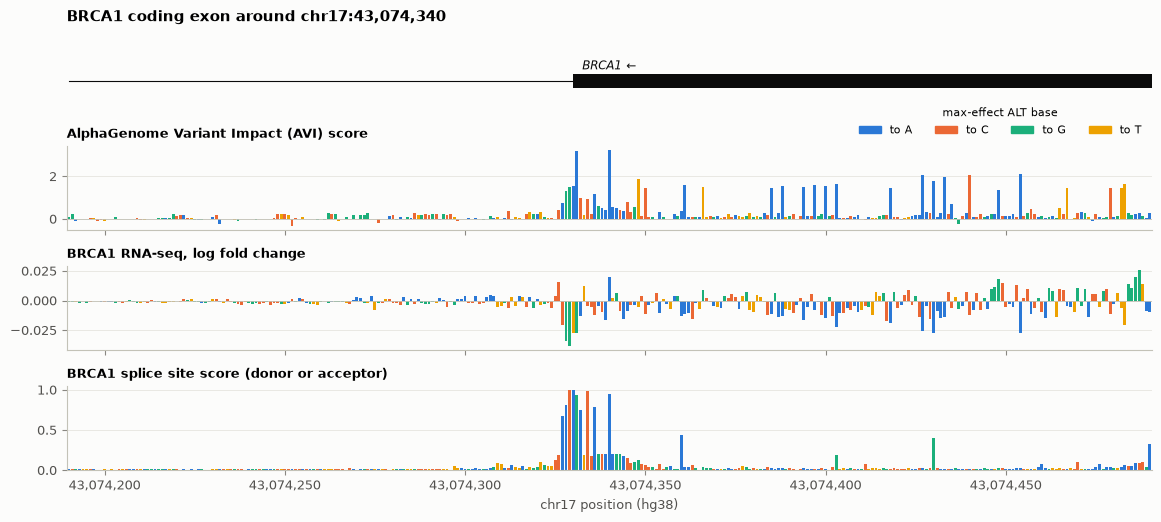

In [9]:
# A coding exon and its splice sites: the CDS position with the highest AVI score.
top_cds = MAXEFF.loc[MAXEFF.region == 'CDS', 'AVI_SCORE:AVI_SCORE'].idxmax()
fig = plot_zoom(top_cds, width=300, tracks=TRACKS[:3],
                title=f'{GENE} coding exon around chr17:{top_cds:,}')

## Coding vs non-coding

Distribution of the per-position maximum effect in each part of the locus
(box: quartiles, whiskers: 5th-95th percentile).

,n_positions,median_AVI,p99_AVI,frac_AVI_quantile_above_0_99,p99_abs_RNA
region,,,,,
5' flank,23636,0.0321,0.4787,0.0049,0.0040
promoter (1 kb),1000,0.1125,0.9269,0.0710,0.1557
UTR,1499,0.1224,0.6757,0.0254,0.0810
CDS,5589,0.3605,2.3970,0.3360,0.0335
intron,73982,0.0280,0.5163,0.0080,0.0164
3' flank,14294,0.0361,0.6616,0.0203,0.0070


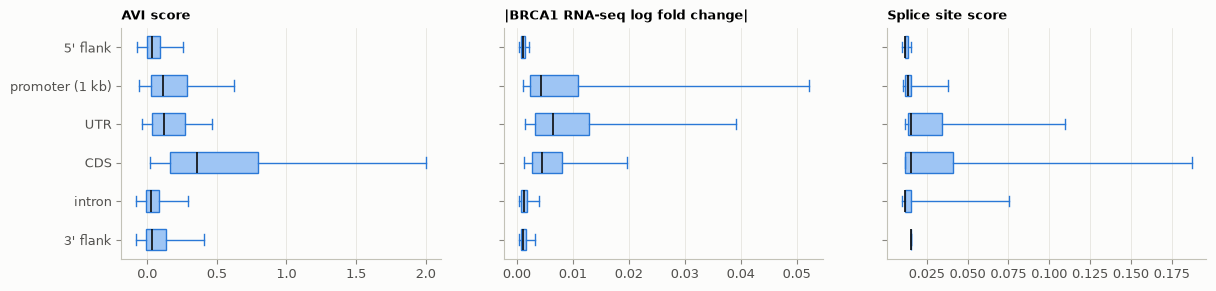

In [10]:
SUMMARY_TRACKS = [
    ('AVI score', 'AVI_SCORE:AVI_SCORE', False),
    ('|BRCA1 RNA-seq log fold change|', 'RNA_SEQ:polyA plus RNA-seq', True),
    ('Splice site score', 'SPLICE_SITES:max', False),
]
fig, axes = plt.subplots(1, len(SUMMARY_TRACKS), figsize=(14, 3), sharey=True)
for ax, (title, col, signed) in zip(axes, SUMMARY_TRACKS):
    values = MAXEFF[col].abs() if signed else MAXEFF[col]
    data = [values[MAXEFF.region == r].dropna() for r in REGION_ORDER[::-1]]
    ax.boxplot(
        data, orientation='horizontal', whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True,
        boxprops=dict(facecolor='#9ec5f4', edgecolor=MAGNITUDE),
        medianprops=dict(color=INK, lw=1.2),
        whiskerprops=dict(color=MAGNITUDE), capprops=dict(color=MAGNITUDE),
    )
    ax.set_yticks(range(1, len(REGION_ORDER) + 1), REGION_ORDER[::-1])
    ax.set_title(title)
    ax.grid(axis='x', color=GRID, lw=0.5)
    ax.set_axisbelow(True)
fig.savefig(f'atlas_ism_{GENE}_regions.png', dpi=200, bbox_inches='tight')

(
    MAXEFF.assign(abs_rna=MAXEFF[rna].abs())
    .groupby('region')
    .agg(
        n_positions=('ref', 'size'),
        median_AVI=('AVI_SCORE:AVI_SCORE', 'median'),
        p99_AVI=('AVI_SCORE:AVI_SCORE', lambda s: s.quantile(0.99)),
        frac_AVI_quantile_above_0_99=('AVI_SCORE:AVI_SCORE|q', lambda s: (s > 0.99).mean()),
        p99_abs_RNA=('abs_rna', lambda s: s.quantile(0.99)),
    )
    .loc[REGION_ORDER]
    .round(4)
)

## Strongest non-coding positions

In [11]:
# dist_to_TSS is strand-aware: negative = upstream of the BRCA1 TSS.
sign = -1 if tx.Strand == '-' else 1
noncoding = MAXEFF[MAXEFF.region != 'CDS'].assign(dist_to_TSS=lambda d: sign * (d.index - TSS))
cols = ['region', 'dist_to_TSS', 'ref', 'AVI_SCORE:AVI_SCORE|alt', 'AVI_SCORE:AVI_SCORE',
        rna + '|alt', rna, 'SPLICE_SITES:max']
print('Top 15 non-coding positions by AVI score')
display(noncoding.nlargest(15, 'AVI_SCORE:AVI_SCORE')[cols])
print('Top 15 non-coding positions by |BRCA1 RNA-seq effect|')
noncoding.loc[noncoding[rna].abs().nlargest(15).index, cols]

Top 15 non-coding positions by AVI score


,region,dist_to_TSS,ref,AVI_SCORE:AVI_SCORE|alt,AVI_SCORE:AVI_SCORE,RNA_SEQ:polyA plus RNA-seq|alt,RNA_SEQ:polyA plus RNA-seq,SPLICE_SITES:max
pos,,,,,,,,
43082403,intron,42961,C,G,2.013779,T,-0.073909,0.994286
43090943,intron,34421,C,G,2.011708,T,-0.107050,0.996032
43063332,intron,62032,C,G,1.946036,T,-0.067834,0.998543
43124016,intron,1348,C,G,1.931471,G,-0.036254,0.992184
43076487,intron,48877,C,G,1.920464,T,-0.025302,0.996080
43067696,intron,57668,C,G,1.902161,G,-0.015745,0.996091
43057051,intron,68313,C,G,1.884523,A,-0.128316,0.986023
43124012,intron,1352,C,G,1.882411,T,-0.035767,0.927246
43063952,intron,61412,C,G,1.877663,T,-0.009727,0.996068


Top 15 non-coding positions by |BRCA1 RNA-seq effect|


,region,dist_to_TSS,ref,AVI_SCORE:AVI_SCORE|alt,AVI_SCORE:AVI_SCORE,RNA_SEQ:polyA plus RNA-seq|alt,RNA_SEQ:polyA plus RNA-seq,SPLICE_SITES:max
pos,,,,,,,,
43125409,promoter (1 kb),-45,C,A,1.708142,A,-0.309016,0.179688
43044317,UTR,81047,T,G,0.768212,G,-0.300040,0.057617
43044318,UTR,81046,A,T,0.858867,G,-0.297203,0.053711
43044315,UTR,81049,T,C,0.750240,C,-0.296462,0.052734
43044316,UTR,81048,T,C,0.715129,C,-0.279164,0.050781
43044319,UTR,81045,T,G,0.765466,G,-0.276426,0.051758
43125410,promoter (1 kb),-46,G,A,1.620975,A,-0.274743,0.164062
43125411,promoter (1 kb),-47,C,A,1.701784,T,-0.268804,0.171875
43044320,UTR,81044,T,C,0.626838,C,-0.251325,0.049805
